In [ ]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
df= pd.read_csv("tabela_final.csv")

In [ ]:
df.head()

,Ano_do_Censo,Nome_do_Municipio,Codigo_da_Escola,Nome_da_Escola,Quantidade_de_Matriculados_Ensino_Medio,Aprovacao_EM_Total,Reprovacao_EM_Total,Abandono_EM_Total
0,2017,SÃO GONÇALO,33051879,CE DOUTOR MOACYR MEIRELLES PADILHA,584.0,69.9,19.2,10.9
1,2018,SÃO GONÇALO,33051879,CE DOUTOR MOACYR MEIRELLES PADILHA,476.0,64.3,31.8,3.9
2,2019,SÃO GONÇALO,33051879,CE DOUTOR MOACYR MEIRELLES PADILHA,435.0,70.4,16.7,12.9
3,2020,SÃO GONÇALO,33051879,CE DOUTOR MOACYR MEIRELLES PADILHA,379.0,97.6,0.0,2.4
4,2021,SÃO GONÇALO,33051879,CE DOUTOR MOACYR MEIRELLES PADILHA,382.0,94.3,5.2,0.5


##Regressão Linear Simples

Regressão Linear Simples excluindo 2020 e 2021

In [ ]:
anos_treino = [2015, 2016, 2017, 2018, 2019, 2022, 2023]
anos_teste = [2024, 2025]

resultados = []
modelos = {}
previsoes = []

for cidade in df['Nome_do_Municipio'].dropna().unique():

    dados_cidade = df[df['Nome_do_Municipio'] == cidade].copy()

    dados_cidade = dados_cidade.dropna(
        subset=['Codigo_da_Escola', 'Ano_do_Censo', 'Quantidade_de_Matriculados_Ensino_Medio', 'Abandono_EM_Total']
    )

    treino = dados_cidade[
        dados_cidade['Ano_do_Censo'].isin(anos_treino)
    ]

    teste = dados_cidade[
        dados_cidade['Ano_do_Censo'].isin(anos_teste)
    ]

    if treino.empty or teste.empty:
        print(f"Dados insuficientes para {cidade}")
        continue

    X_treino = treino[['Quantidade_de_Matriculados_Ensino_Medio']]
    y_treino = treino['Abandono_EM_Total']

    X_teste = teste[['Quantidade_de_Matriculados_Ensino_Medio']]
    y_teste = teste['Abandono_EM_Total']


    modelo = LinearRegression()
    modelo.fit(X_treino, y_treino)

    modelos[cidade] = modelo

    y_pred = modelo.predict(X_teste)

    resultados.append({
        'Cidade': cidade,
        'Observacoes_treino': len(treino),
        'Observacoes_teste': len(teste),
        'Intercepto': modelo.intercept_,
        'Coeficiente': modelo.coef_[0],
        'MAE_teste': mean_absolute_error(y_teste, y_pred),
        'RMSE_teste': np.sqrt(mean_squared_error(y_teste, y_pred)),
        'R2_teste': (
            r2_score(y_teste, y_pred)
            if len(y_teste) >= 2 else np.nan
        )
    })

    # Guardar os valores reais e previstos
    previsoes_cidade = teste[
        ['Codigo_da_Escola','Nome_do_Municipio', 'Ano_do_Censo', 'Quantidade_de_Matriculados_Ensino_Medio', 'Abandono_EM_Total']
    ].copy()

    previsoes_cidade['Taxa_Abandono_Prevista'] = y_pred

    previsoes.append(previsoes_cidade)

resultado_modelos = pd.DataFrame(resultados)

print("Desempenho dos modelos por cidade:")
display(resultado_modelos.round(4))

if previsoes:
    resultado_previsoes = pd.concat(previsoes, ignore_index=True)

    print("Previsões para 2024 e 2025:")

resultado_previsoes['Erro'] = (
    resultado_previsoes['Abandono_EM_Total']
    - resultado_previsoes['Taxa_Abandono_Prevista']
)

resultado_previsoes['Erro_Absoluto'] = (
    resultado_previsoes['Erro'].abs()
)

display(resultado_previsoes.round(2))

Desempenho dos modelos por cidade:


,Cidade,Observacoes_treino,Observacoes_teste,Intercepto,Coeficiente,MAE_teste,RMSE_teste,R2_teste
0,SÃO GONÇALO,458,135,6.8901,-0.0035,4.2211,4.8948,-0.1759
1,MARICÁ,63,20,7.1786,-0.0010,4.8624,6.0791,-0.0080
2,NITERÓI,240,72,7.0551,-0.0019,4.9372,5.6946,-0.0370
3,RIO DE JANEIRO,1786,509,13.4916,-0.0047,6.6516,8.0496,-0.0575


Previsões para 2024 e 2025:


,Codigo_da_Escola,Nome_do_Municipio,Ano_do_Censo,Quantidade_de_Matriculados_Ensino_Medio,Abandono_EM_Total,Taxa_Abandono_Prevista,Erro,Erro_Absoluto
0,33051879,SÃO GONÇALO,2024,308.0,12.1,5.82,6.28,6.28
1,33088870,SÃO GONÇALO,2024,83.0,11.9,6.60,5.30,5.30
2,33088870,SÃO GONÇALO,2025,83.0,8.5,6.60,1.90,1.90
3,33088896,SÃO GONÇALO,2024,84.0,0.0,6.60,-6.60,6.60
4,33088896,SÃO GONÇALO,2025,72.0,3.1,6.64,-3.54,3.54
...,...,...,...,...,...,...,...,...
731,33439222,RIO DE JANEIRO,2025,488.0,6.4,11.19,-4.79,4.79
732,33508232,RIO DE JANEIRO,2024,367.0,4.2,11.76,-7.56,7.56
733,33508232,RIO DE JANEIRO,2025,314.0,4.1,12.01,-7.91,7.91
734,33558230,RIO DE JANEIRO,2024,1070.0,16.1,8.46,7.64,7.64


Regressão Linear Simples incluindo 2020 e 2021

In [ ]:
anos_treino = [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]
anos_teste = [2024, 2025]

resultados = []
modelos = {}
previsoes = []

for cidade in df['Nome_do_Municipio'].dropna().unique():

    dados_cidade = df[df['Nome_do_Municipio'] == cidade].copy()

    dados_cidade = dados_cidade.dropna(
        subset=['Codigo_da_Escola', 'Ano_do_Censo', 'Quantidade_de_Matriculados_Ensino_Medio', 'Abandono_EM_Total']
    )

    treino = dados_cidade[
        dados_cidade['Ano_do_Censo'].isin(anos_treino)
    ]

    teste = dados_cidade[
        dados_cidade['Ano_do_Censo'].isin(anos_teste)
    ]

    if treino.empty or teste.empty:
        print(f"Dados insuficientes para {cidade}")
        continue

    X_treino = treino[['Quantidade_de_Matriculados_Ensino_Medio']]
    y_treino = treino['Abandono_EM_Total']

    X_teste = teste[['Quantidade_de_Matriculados_Ensino_Medio']]
    y_teste = teste['Abandono_EM_Total']

    modelo1 = LinearRegression()
    modelo1.fit(X_treino, y_treino)

    modelos[cidade] = modelo1

    y_pred = modelo1.predict(X_teste)

    resultados.append({
        'Cidade': cidade,
        'Observacoes_treino': len(treino),
        'Observacoes_teste': len(teste),
        'Intercepto': modelo1.intercept_,
        'Coeficiente': modelo1.coef_[0],
        'MAE_teste': mean_absolute_error(y_teste, y_pred),
        'RMSE_teste': np.sqrt(mean_squared_error(y_teste, y_pred)),
        'R2_teste': (
            r2_score(y_teste, y_pred)
            if len(y_teste) >= 2 else np.nan
        )
    })

    previsoes_cidade = teste[
        ['Codigo_da_Escola','Nome_do_Municipio', 'Ano_do_Censo', 'Quantidade_de_Matriculados_Ensino_Medio', 'Abandono_EM_Total']
    ].copy()

    previsoes_cidade['Taxa_Abandono_Prevista'] = y_pred

    previsoes.append(previsoes_cidade)

resultado_modelos1 = pd.DataFrame(resultados)

print("Desempenho dos modelos por cidade:")
display(resultado_modelos1.round(4))

if previsoes:
    resultado_previsoes1 = pd.concat(previsoes, ignore_index=True)

    print("Previsões para 2024 e 2025:")

resultado_previsoes1['Erro'] = (
    resultado_previsoes1['Abandono_EM_Total']
    - resultado_previsoes1['Taxa_Abandono_Prevista']
)

resultado_previsoes1['Erro_Absoluto'] = (
    resultado_previsoes1['Erro'].abs()
)

display(resultado_previsoes1.round(2))

Desempenho dos modelos por cidade:


,Cidade,Observacoes_treino,Observacoes_teste,Intercepto,Coeficiente,MAE_teste,RMSE_teste,R2_teste
0,SÃO GONÇALO,594,135,5.5293,-0.0028,3.7901,4.5497,-0.0159
1,MARICÁ,83,20,6.0270,-0.0015,4.8980,6.2025,-0.0493
2,NITERÓI,310,72,6.1287,-0.0018,4.7726,5.6154,-0.0083
3,RIO DE JANEIRO,2286,509,11.2679,-0.0041,6.1526,7.6037,0.0564


Previsões para 2024 e 2025:


,Codigo_da_Escola,Nome_do_Municipio,Ano_do_Censo,Quantidade_de_Matriculados_Ensino_Medio,Abandono_EM_Total,Taxa_Abandono_Prevista,Erro,Erro_Absoluto
0,33051879,SÃO GONÇALO,2024,308.0,12.1,4.68,7.42,7.42
1,33088870,SÃO GONÇALO,2024,83.0,11.9,5.30,6.60,6.60
2,33088870,SÃO GONÇALO,2025,83.0,8.5,5.30,3.20,3.20
3,33088896,SÃO GONÇALO,2024,84.0,0.0,5.30,-5.30,5.30
4,33088896,SÃO GONÇALO,2025,72.0,3.1,5.33,-2.23,2.23
...,...,...,...,...,...,...,...,...
731,33439222,RIO DE JANEIRO,2025,488.0,6.4,9.28,-2.88,2.88
732,33508232,RIO DE JANEIRO,2024,367.0,4.2,9.77,-5.57,5.57
733,33508232,RIO DE JANEIRO,2025,314.0,4.1,9.99,-5.89,5.89
734,33558230,RIO DE JANEIRO,2024,1070.0,16.1,6.90,9.20,9.20


Comparação

Comparação das métricas por município:


,Município,R² modelo,RMSE modelo,MAE modelo,R² modelo1,RMSE modelo1,MAE modelo1
0,SÃO GONÇALO,-0.176,4.895,4.221,-0.016,4.550,3.790
1,MARICÁ,-0.008,6.079,4.862,-0.049,6.203,4.898
2,NITERÓI,-0.037,5.695,4.937,-0.008,5.615,4.773
3,RIO DE JANEIRO,-0.058,8.050,6.652,0.056,7.604,6.153


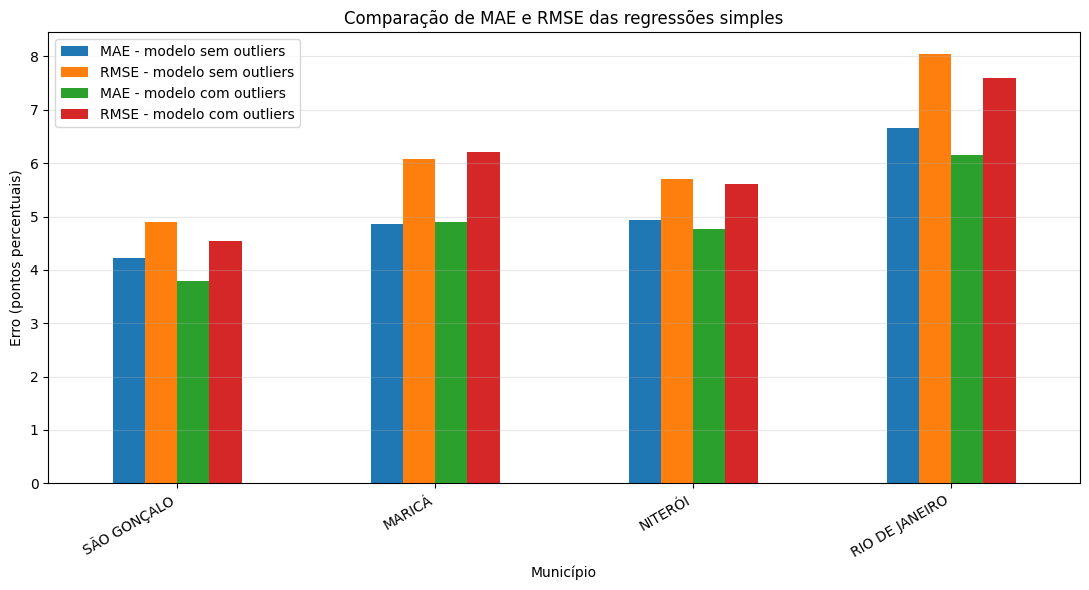

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Selecionar as métricas do modelo
metricas_modelo = resultado_modelos[
    ["Cidade", "MAE_teste", "RMSE_teste", "R2_teste"]
].copy()

metricas_modelo = metricas_modelo.rename(columns={
    "MAE_teste": "MAE_modelo",
    "RMSE_teste": "RMSE_modelo",
    "R2_teste": "R2_modelo"
})

# Selecionar as métricas do modelo1
metricas_modelo1 = resultado_modelos1[
    ["Cidade", "MAE_teste", "RMSE_teste", "R2_teste"]
].copy()

metricas_modelo1 = metricas_modelo1.rename(columns={
    "MAE_teste": "MAE_modelo1",
    "RMSE_teste": "RMSE_modelo1",
    "R2_teste": "R2_modelo1"
})

# Unir as tabelas por município
comparacao = metricas_modelo.merge(
    metricas_modelo1,
    on="Cidade",
    how="inner"
)

# Criar tabela organizada com as métricas dos dois modelos
tabela_metricas = comparacao[
    [
        "Cidade",
        "R2_modelo", "RMSE_modelo", "MAE_modelo",
        "R2_modelo1", "RMSE_modelo1", "MAE_modelo1"
    ]
].copy()

tabela_metricas.columns = [
    "Município",
    "R² modelo", "RMSE modelo", "MAE modelo",
    "R² modelo1", "RMSE modelo1", "MAE modelo1"
]

print("Comparação das métricas por município:")
display(tabela_metricas.round(3))

# Gráfico comparativo de MAE e RMSE
grafico = comparacao.set_index("Cidade")[
    ["MAE_modelo", "RMSE_modelo",
     "MAE_modelo1", "RMSE_modelo1"]
]

ax = grafico.plot(kind="bar", figsize=(11, 6))

ax.set_ylabel("Erro (pontos percentuais)")
ax.set_xlabel("Município")
ax.set_title("Comparação de MAE e RMSE das regressões simples")
ax.legend([
    "MAE - modelo sem outliers",
    "RMSE - modelo sem outliers",
    "MAE - modelo com outliers",
    "RMSE - modelo com outliers"
])

plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



Visualizações

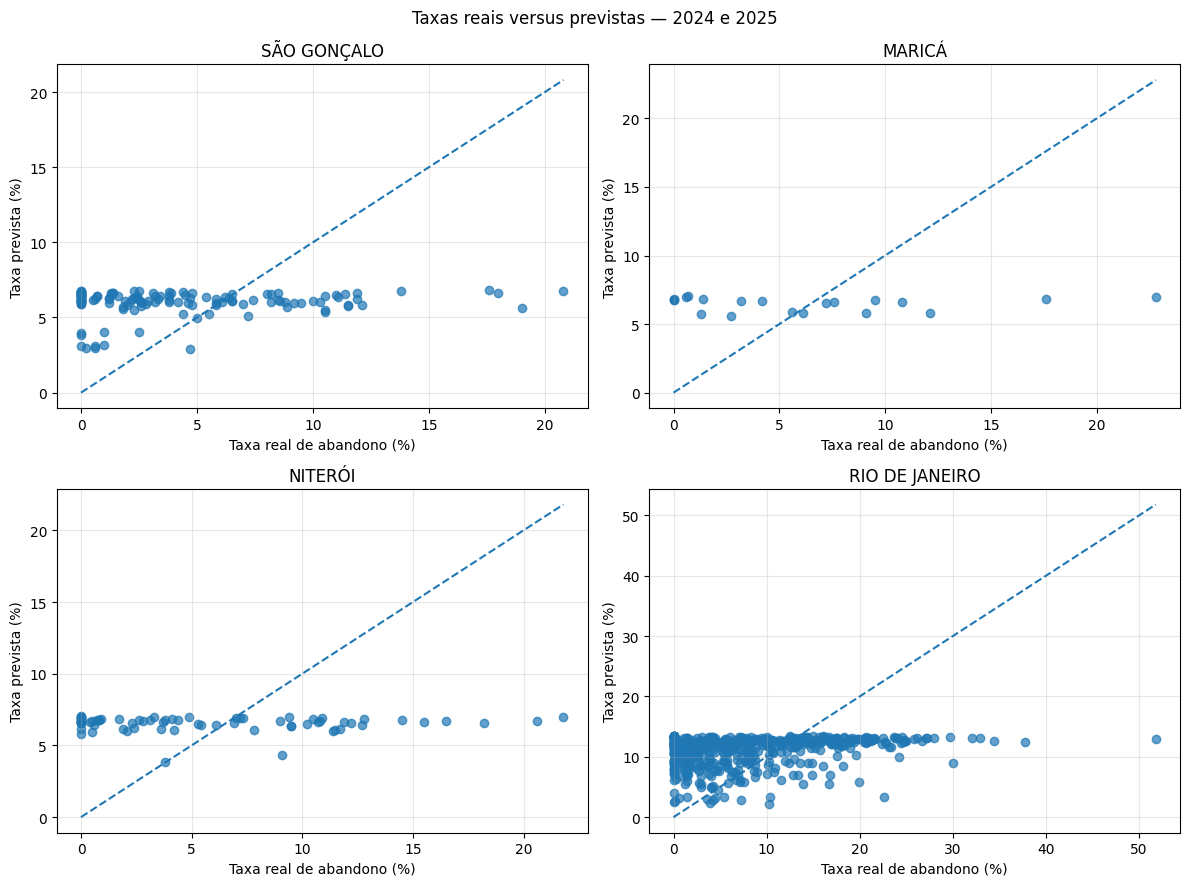

In [ ]:
cidades = resultado_previsoes['Nome_do_Municipio'].unique()

fig, eixos = plt.subplots(
    2, 2, figsize=(12, 9), sharex=False, sharey=False
)

for ax, cidade in zip(eixos.flatten(), cidades):
    dados = resultado_previsoes[
        resultado_previsoes['Nome_do_Municipio'] == cidade
    ]

    ax.scatter(
        dados['Abandono_EM_Total'],
        dados['Taxa_Abandono_Prevista'],
        alpha=0.7
    )

    minimo = min(
        dados['Abandono_EM_Total'].min(),
        dados['Taxa_Abandono_Prevista'].min()
    )
    maximo = max(
        dados['Abandono_EM_Total'].max(),
        dados['Taxa_Abandono_Prevista'].max()
    )

    ax.plot([minimo, maximo], [minimo, maximo], '--')

    ax.set_title(cidade)
    ax.set_xlabel('Taxa real de abandono (%)')
    ax.set_ylabel('Taxa prevista (%)')
    ax.grid(True, alpha=0.3)

plt.suptitle('Taxas reais versus previstas — 2024 e 2025')
plt.tight_layout()
plt.show()

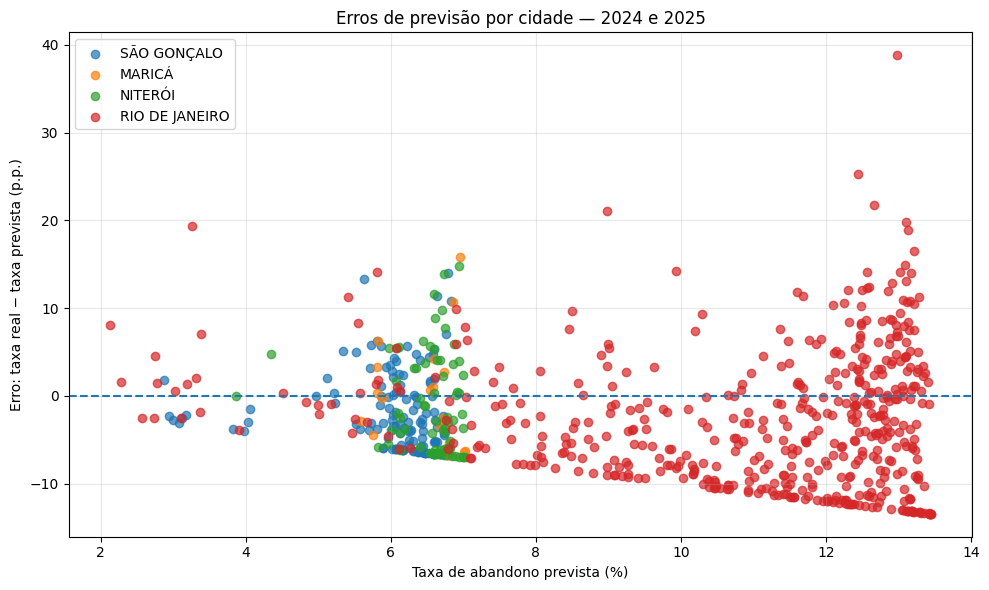

In [ ]:
resultado_previsoes['Erro'] = (
    resultado_previsoes['Abandono_EM_Total']
    - resultado_previsoes['Taxa_Abandono_Prevista']
)

fig, ax = plt.subplots(figsize=(10, 6))

for cidade in resultado_previsoes['Nome_do_Municipio'].unique():
    dados = resultado_previsoes[
        resultado_previsoes['Nome_do_Municipio'] == cidade
    ]

    ax.scatter(
        dados['Taxa_Abandono_Prevista'],
        dados['Erro'],
        label=cidade,
        alpha=0.7
    )

ax.axhline(y=0, linestyle='--')
ax.set_xlabel('Taxa de abandono prevista (%)')
ax.set_ylabel('Erro: taxa real − taxa prevista (p.p.)')
ax.set_title('Erros de previsão por cidade — 2024 e 2025')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
resumo = resultado_previsoes.groupby('Nome_do_Municipio').agg(
    Taxa_real_media=('Abandono_EM_Total', 'mean'),
    Taxa_prevista_media=('Taxa_Abandono_Prevista', 'mean'),
    Erro_medio=('Erro', 'mean'),
    Erro_absoluto_medio=('Erro', lambda x: x.abs().mean()),
    Desvio_padrao_real=('Abandono_EM_Total', 'std'),
    Numero_observacoes=('Erro', 'count')
).reset_index()

display(resumo.round(2))

,Nome_do_Municipio,Taxa_real_media,Taxa_prevista_media,Erro_medio,Erro_absoluto_medio,Desvio_padrao_real,Numero_observacoes
0,MARICÁ,6.12,6.48,-0.35,4.86,6.21,20
1,NITERÓI,5.61,6.54,-0.93,4.94,5.63,72
2,RIO DE JANEIRO,8.19,10.94,-2.75,6.65,7.84,509
3,SÃO GONÇALO,4.08,6.02,-1.94,4.22,4.53,135


##Regressão Linear Múltipla

###Regressões Lineares Múltiplas utilizando "cidade base"

In [ ]:
# 2. Codificando as cidades (One-Hot Encoding)
df_codificado = pd.get_dummies(df, columns=['Nome_do_Municipio'])

In [ ]:
df_codificado.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 11 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Ano_do_Censo                             4009 non-null   int64  
 1   Codigo_da_Escola                         4009 non-null   int64  
 2   Nome_da_Escola                           4009 non-null   object 
 3   Quantidade_de_Matriculados_Ensino_Medio  4009 non-null   float64
 4   Aprovacao_EM_Total                       4009 non-null   float64
 5   Reprovacao_EM_Total                      4009 non-null   float64
 6   Abandono_EM_Total                        4009 non-null   float64
 7   Nome_do_Municipio_MARICÁ                 4009 non-null   bool   
 8   Nome_do_Municipio_NITERÓI                4009 non-null   bool   
 9   Nome_do_Municipio_RIO DE JANEIRO         4009 non-null   bool   
 10  Nome_do_Municipio_SÃO GONÇALO            4009 no

Regressão Linear Múltipla com todos os anos incluídos

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Definir as colunas
col_escola = "Codigo_da_Escola"
col_municipio = "Nome_do_Municipio"
col_ano = "Ano_do_Censo"
col_matriculados = "Quantidade_de_Matriculados_Ensino_Medio"
col_reprovacao = "Reprovacao_EM_Total"
col_alvo = "Abandono_EM_Total"

# 2. Preparar os dados
dados = df.copy()

dados[col_ano] = pd.to_numeric(dados[col_ano], errors="coerce")
dados[col_matriculados] = pd.to_numeric(
    dados[col_matriculados], errors="coerce"
)
dados[col_reprovacao] = pd.to_numeric(
    dados[col_reprovacao], errors="coerce"
)
dados[col_alvo] = pd.to_numeric(
    dados[col_alvo], errors="coerce"
)

# Ordenar por escola e ano para criar a variável histórica
dados = dados.sort_values([col_escola, col_ano]).copy()

# 3. Criar a reprovação do ano anterior de cada escola
dados["Reprovacao_Ano_Anterior"] = (
    dados.groupby(col_escola)[col_reprovacao].shift(1)
)

# 4. Definir os anos de treino e teste
anos_treino = [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]
anos_teste = [2024, 2025]

# 5. Selecionar as variáveis
colunas_numericas = [
    col_matriculados,
    col_ano,
    "Reprovacao_Ano_Anterior"
]

colunas_categoricas = [col_municipio]

colunas_modelo = (
    colunas_numericas + colunas_categoricas + [col_alvo]
)

# Remover registros sem informações essenciais
dados_modelo = dados.dropna(
    subset=[
        col_escola,
        col_municipio,
        col_ano,
        col_matriculados,
        "Reprovacao_Ano_Anterior",
        col_alvo
    ]
).copy()

# Selecionar treino e teste por ano
treino = dados_modelo[
    dados_modelo[col_ano].isin(anos_treino)
].copy()

teste = dados_modelo[
    dados_modelo[col_ano].isin(anos_teste)
].copy()

X_train = treino[colunas_numericas + colunas_categoricas]
y_train = treino[col_alvo]

X_test = teste[colunas_numericas + colunas_categoricas]
y_test = teste[col_alvo]

# 6. Preparar os preditores
preprocessador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            SimpleImputer(strategy="median"),
            colunas_numericas
        ),
        (
            "categoricas",
            Pipeline(steps=[
                (
                    "imputador",
                    SimpleImputer(strategy="most_frequent")
                ),
                (
                    "codificador",
                    OneHotEncoder(
                        drop="first",
                        handle_unknown="ignore"
                    )
                )
            ]),
            colunas_categoricas
        )
    ]
)

# 7. Criar e treinar o modelo
modelo = Pipeline(steps=[
    ("preprocessador", preprocessador),
    ("regressao", LinearRegression())
])

modelo.fit(X_train, y_train)

# 8. Gerar previsões
y_pred = modelo.predict(X_test)

# 9. Avaliar o desempenho geral
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("=== AVALIAÇÃO GERAL ===")
print(f"Registros de treino: {len(X_train)}")
print(f"Registros de teste: {len(X_test)}")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

# 10. Criar dataframe com as previsões
resultado_previsoes = teste[
    [col_escola, col_municipio, col_ano,
     col_matriculados, col_alvo]
].copy()

resultado_previsoes["Abandono_Previsto"] = y_pred

resultado_previsoes["Erro"] = (
    resultado_previsoes[col_alvo]
    - resultado_previsoes["Abandono_Previsto"]
)

resultado_previsoes["Erro_Absoluto"] = (
    resultado_previsoes["Erro"].abs()
)

print("\n=== AMOSTRA DAS PREVISÕES ===")
display(resultado_previsoes.head(10))

# 11. Avaliação por município
avaliacao_municipios = (
    resultado_previsoes
    .groupby(col_municipio)
    .apply(
        lambda grupo: pd.Series({
            "Registros": len(grupo),
            "Abandono_Medio_Real": grupo[col_alvo].mean(),
            "Abandono_Medio_Previsto":
                grupo["Abandono_Previsto"].mean(),
            "MAE": mean_absolute_error(
                grupo[col_alvo],
                grupo["Abandono_Previsto"]
            ),
            "RMSE": np.sqrt(mean_squared_error(
                grupo[col_alvo],
                grupo["Abandono_Previsto"]
            )),
            "R2": (
                r2_score(
                    grupo[col_alvo],
                    grupo["Abandono_Previsto"]
                )
                if len(grupo) >= 2
                and grupo[col_alvo].nunique() > 1
                else np.nan
            )
        }),
        include_groups=False
    )
    .reset_index()
)

print("\n=== AVALIAÇÃO POR MUNICÍPIO ===")
display(avaliacao_municipios)

=== AVALIAÇÃO GERAL ===
Registros de treino: 2892
Registros de teste: 732
MAE:  5.2997
RMSE: 7.0016
R²:   0.0739

=== AMOSTRA DAS PREVISÕES ===


,Codigo_da_Escola,Nome_do_Municipio,Ano_do_Censo,Quantidade_de_Matriculados_Ensino_Medio,Abandono_EM_Total,Abandono_Previsto,Erro,Erro_Absoluto
7,33051879,SÃO GONÇALO,2024,308.0,12.1,3.843124,8.256876,8.256876
17,33053910,MARICÁ,2024,1373.0,12.1,0.459050,11.640950,11.640950
18,33053910,MARICÁ,2025,1443.0,1.3,-0.251444,1.551444,1.551444
28,33053952,MARICÁ,2024,390.0,0.0,3.893105,-3.893105,3.893105
29,33053952,MARICÁ,2025,381.0,0.0,3.407206,-3.407206,3.407206
37,33053995,MARICÁ,2024,170.0,0.6,4.731950,-4.131950,4.131950
38,33053995,MARICÁ,2025,152.0,0.7,4.714786,-4.014786,4.014786
48,33054177,MARICÁ,2024,651.0,7.2,3.191034,4.008966,4.008966
49,33054177,MARICÁ,2025,606.0,7.6,3.253429,4.346571,4.346571
59,33054185,MARICÁ,2024,586.0,10.8,3.022242,7.777758,7.777758



=== AVALIAÇÃO POR MUNICÍPIO ===


,Nome_do_Municipio,Registros,Abandono_Medio_Real,Abandono_Medio_Previsto,MAE,RMSE,R2
0,MARICÁ,20.0,6.125000,2.798230,5.623651,7.012925,-0.341479
1,NITERÓI,71.0,5.687324,3.830632,4.514548,5.777046,-0.067529
2,RIO DE JANEIRO,506.0,8.184387,6.839830,5.931002,7.657473,0.044566
3,SÃO GONÇALO,135.0,4.076296,2.676205,3.298247,4.603555,-0.040126


Regressão linear múltipla excluindo 2020 e 2021

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Definir as colunas
col_escola = "Codigo_da_Escola"
col_municipio = "Nome_do_Municipio"
col_ano = "Ano_do_Censo"
col_matriculados = "Quantidade_de_Matriculados_Ensino_Medio"
col_reprovacao = "Reprovacao_EM_Total"
col_alvo = "Abandono_EM_Total"

# 2. Preparar os dados
dados = df.copy()

dados[col_ano] = pd.to_numeric(dados[col_ano], errors="coerce")
dados[col_matriculados] = pd.to_numeric(
    dados[col_matriculados], errors="coerce"
)
dados[col_reprovacao] = pd.to_numeric(
    dados[col_reprovacao], errors="coerce"
)
dados[col_alvo] = pd.to_numeric(
    dados[col_alvo], errors="coerce"
)

# Ordenar por escola e ano para criar a variável histórica
dados = dados.sort_values([col_escola, col_ano]).copy()

# 3. Criar a reprovação do ano anterior de cada escola
dados["Reprovacao_Ano_Anterior"] = (
    dados.groupby(col_escola)[col_reprovacao].shift(1)
)

# 4. Definir os anos de treino e teste
anos_treino = [2015, 2016, 2017, 2018, 2019, 2022, 2023]
anos_teste = [2024, 2025]

# 5. Selecionar as variáveis
colunas_numericas = [
    col_matriculados,
    col_ano,
    "Reprovacao_Ano_Anterior"
]

colunas_categoricas = [col_municipio]

colunas_modelo = (
    colunas_numericas + colunas_categoricas + [col_alvo]
)

# Remover registros sem informações essenciais
dados_modelo = dados.dropna(
    subset=[
        col_escola,
        col_municipio,
        col_ano,
        col_matriculados,
        "Reprovacao_Ano_Anterior",
        col_alvo
    ]
).copy()

# Selecionar treino e teste por ano
treino = dados_modelo[
    dados_modelo[col_ano].isin(anos_treino)
].copy()

teste = dados_modelo[
    dados_modelo[col_ano].isin(anos_teste)
].copy()

X_train = treino[colunas_numericas + colunas_categoricas]
y_train = treino[col_alvo]

X_test = teste[colunas_numericas + colunas_categoricas]
y_test = teste[col_alvo]

# 6. Preparar os preditores
preprocessador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            SimpleImputer(strategy="median"),
            colunas_numericas
        ),
        (
            "categoricas",
            Pipeline(steps=[
                (
                    "imputador",
                    SimpleImputer(strategy="most_frequent")
                ),
                (
                    "codificador",
                    OneHotEncoder(
                        drop="first",
                        handle_unknown="ignore"
                    )
                )
            ]),
            colunas_categoricas
        )
    ]
)

# 7. Criar e treinar o modelo
modelo0 = Pipeline(steps=[
    ("preprocessador", preprocessador),
    ("regressao", LinearRegression())
])

modelo0.fit(X_train, y_train)

# 8. Gerar previsões
y_pred = modelo0.predict(X_test)

# 9. Avaliar o desempenho geral
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("=== AVALIAÇÃO GERAL ===")
print(f"Registros de treino: {len(X_train)}")
print(f"Registros de teste: {len(X_test)}")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

# 10. Criar dataframe com as previsões
resultado_previsoes0 = teste[
    [col_escola, col_municipio, col_ano,
     col_matriculados, col_alvo]
].copy()

resultado_previsoes0["Abandono_Previsto"] = y_pred

resultado_previsoes0["Erro"] = (
    resultado_previsoes0[col_alvo]
    - resultado_previsoes0["Abandono_Previsto"]
)

resultado_previsoes0["Erro_Absoluto"] = (
    resultado_previsoes0["Erro"].abs()
)

print("\n=== AMOSTRA DAS PREVISÕES ===")
display(resultado_previsoes0.head(10))

# 11. Avaliação por município
avaliacao_municipios = (
    resultado_previsoes0
    .groupby(col_municipio)
    .apply(
        lambda grupo: pd.Series({
            "Registros": len(grupo),
            "Abandono_Medio_Real": grupo[col_alvo].mean(),
            "Abandono_Medio_Previsto":
                grupo["Abandono_Previsto"].mean(),
            "MAE": mean_absolute_error(
                grupo[col_alvo],
                grupo["Abandono_Previsto"]
            ),
            "RMSE": np.sqrt(mean_squared_error(
                grupo[col_alvo],
                grupo["Abandono_Previsto"]
            )),
            "R2": (
                r2_score(
                    grupo[col_alvo],
                    grupo["Abandono_Previsto"]
                )
                if len(grupo) >= 2
                and grupo[col_alvo].nunique() > 1
                else np.nan
            )
        }),
        include_groups=False
    )
    .reset_index()
)

print("\n=== AVALIAÇÃO POR MUNICÍPIO ===")
display(avaliacao_municipios)


=== AVALIAÇÃO GERAL ===
Registros de treino: 2170
Registros de teste: 732
MAE:  5.8747
RMSE: 7.1910
R²:   0.0231

=== AMOSTRA DAS PREVISÕES ===


,Codigo_da_Escola,Nome_do_Municipio,Ano_do_Censo,Quantidade_de_Matriculados_Ensino_Medio,Abandono_EM_Total,Abandono_Previsto,Erro,Erro_Absoluto
7,33051879,SÃO GONÇALO,2024,308.0,12.1,6.578447,5.521553,5.521553
17,33053910,MARICÁ,2024,1373.0,12.1,2.743352,9.356648,9.356648
18,33053910,MARICÁ,2025,1443.0,1.3,2.307309,-1.007309,1.007309
28,33053952,MARICÁ,2024,390.0,0.0,6.832382,-6.832382,6.832382
29,33053952,MARICÁ,2025,381.0,0.0,6.668706,-6.668706,6.668706
37,33053995,MARICÁ,2024,170.0,0.6,7.824470,-7.224470,7.224470
38,33053995,MARICÁ,2025,152.0,0.7,8.176939,-7.476939,7.476939
48,33054177,MARICÁ,2024,651.0,7.2,5.976267,1.223733,1.223733
49,33054177,MARICÁ,2025,606.0,7.6,6.424887,1.175113,1.175113
59,33054185,MARICÁ,2024,586.0,10.8,5.813296,4.986704,4.986704



=== AVALIAÇÃO POR MUNICÍPIO ===


,Nome_do_Municipio,Registros,Abandono_Medio_Real,Abandono_Medio_Previsto,MAE,RMSE,R2
0,MARICÁ,20.0,6.125000,5.709517,5.253840,6.286411,-0.077931
1,NITERÓI,71.0,5.687324,6.394958,4.770110,5.511586,0.028324
2,RIO DE JANEIRO,506.0,8.184387,10.617231,6.574377,7.954518,-0.030997
3,SÃO GONÇALO,135.0,4.076296,5.501520,3.924979,4.625014,-0.049846


###Regressão com codificação por efeitos

Regressão com codificação por efeitos: compara os municípios com uma média geral ajustada, sem privilegiar uma cidade como referência interpretativa.

Excluindo 2020 e 2021

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Definir as colunas
col_escola = "Codigo_da_Escola"
col_municipio = "Nome_do_Municipio"
col_ano = "Ano_do_Censo"
col_matriculados = "Quantidade_de_Matriculados_Ensino_Medio"
col_reprovacao = "Reprovacao_EM_Total"
col_alvo = "Abandono_EM_Total"

# 2. Preparar os dados
dados = df.copy()

for coluna in [
    col_ano,
    col_matriculados,
    col_reprovacao,
    col_alvo
]:
    dados[coluna] = pd.to_numeric(
        dados[coluna], errors="coerce"
    )

dados = dados.sort_values(
    [col_escola, col_ano]
).copy()

# 3. Criar reprovação do ano anterior por escola
dados["Reprovacao_Ano_Anterior"] = (
    dados.groupby(col_escola)[col_reprovacao].shift(1)
)

# 4. Definir treino e teste
anos_treino = [2015, 2016, 2017, 2018, 2019, 2022, 2023]
anos_teste = [2024, 2025]

colunas_numericas = [
    col_matriculados,
    col_ano,
    "Reprovacao_Ano_Anterior"
]

# Excluir registros sem dados essenciais
dados_modelo = dados.dropna(
    subset=[
        col_escola,
        col_municipio,
        col_ano,
        col_matriculados,
        "Reprovacao_Ano_Anterior",
        col_alvo
    ]
).copy()

treino = dados_modelo[
    dados_modelo[col_ano].isin(anos_treino)
].copy()

teste = dados_modelo[
    dados_modelo[col_ano].isin(anos_teste)
].copy()

# 5. Criar a codificação por efeitos
# As categorias são definidas pelo conjunto de treino.
municipios = sorted(treino[col_municipio].unique())

if len(municipios) < 2:
    raise ValueError("É necessário ter pelo menos dois municípios.")

# Três colunas para quatro municípios.
# O último município recebe -1 nas três colunas.
def codificar_efeitos(serie):
    if isinstance(serie, pd.DataFrame):
        valores = serie.iloc[:, 0].to_numpy()
    else:
        valores = np.asarray(serie).reshape(-1)

    resultado = np.zeros((len(valores), len(municipios) - 1))

    # Os primeiros municípios recebem 1 na própria coluna
    for i, municipio in enumerate(municipios[:-1]):
        resultado[:, i] = (valores == municipio).astype(float)

    # O último município recebe -1 em todas as colunas
    ultimo = valores == municipios[-1]
    resultado[ultimo, :] = -1

    return resultado


preprocessador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            SimpleImputer(strategy="median"),
            colunas_numericas
        ),
        (
            "municipio",
            Pipeline(steps=[
                (
                    "imputador",
                    SimpleImputer(strategy="most_frequent")
                ),
                (
                    "efeitos",
                    FunctionTransformer(
                        codificar_efeitos,
                        validate=False
                    )
                )
            ]),
            [col_municipio]
        )
    ],
    verbose_feature_names_out=False
)

# 6. Criar e treinar a regressão
modelo_efeitos = Pipeline(steps=[
    ("preprocessador", preprocessador),
    ("regressao", LinearRegression())
])

X_train = treino[
    colunas_numericas + [col_municipio]
]
y_train = treino[col_alvo]

X_test = teste[
    colunas_numericas + [col_municipio]
]
y_test = teste[col_alvo]

modelo_efeitos.fit(X_train, y_train)

# 7. Prever
y_pred = modelo_efeitos.predict(X_test)

# 8. Avaliar
print("=== REGRESSÃO COM CODIFICAÇÃO POR EFEITOS ===")
print("Municípios no treino:", municipios)
print("Registros de treino:", len(X_train))
print("Registros de teste:", len(X_test))
print(f"MAE:  {mean_absolute_error(y_test, y_pred):.4f}")
print(
    f"RMSE: "
    f"{np.sqrt(mean_squared_error(y_test, y_pred)):.4f}"
)
print(f"R²:   {r2_score(y_test, y_pred):.4f}")

# 9. Guardar previsões
resultado_efeitos = teste[
    [col_escola, col_municipio, col_ano, col_alvo]
].copy()

resultado_efeitos["Abandono_Previsto"] = y_pred
resultado_efeitos["Erro"] = (
    resultado_efeitos[col_alvo]
    - resultado_efeitos["Abandono_Previsto"]
)

display(resultado_efeitos.head(10))

nomes_efeitos = [
    f"Municipio_{municipio}"
    for municipio in municipios[:-1]
]

nomes_variaveis = colunas_numericas + nomes_efeitos

coeficientes = pd.DataFrame({
    "Variavel": nomes_variaveis,
    "Coeficiente": modelo_efeitos["regressao"].coef_
})

print("=== COEFICIENTES ===")
display(coeficientes)

print(
    "Intercepto:",
    modelo_efeitos["regressao"].intercept_
)


=== REGRESSÃO COM CODIFICAÇÃO POR EFEITOS ===
Municípios no treino: ['MARICÁ', 'NITERÓI', 'RIO DE JANEIRO', 'SÃO GONÇALO']
Registros de treino: 2170
Registros de teste: 732
MAE:  5.8747
RMSE: 7.1910
R²:   0.0231


,Codigo_da_Escola,Nome_do_Municipio,Ano_do_Censo,Abandono_EM_Total,Abandono_Previsto,Erro
7,33051879,SÃO GONÇALO,2024,12.1,6.578447,5.521553
17,33053910,MARICÁ,2024,12.1,2.743352,9.356648
18,33053910,MARICÁ,2025,1.3,2.307309,-1.007309
28,33053952,MARICÁ,2024,0.0,6.832382,-6.832382
29,33053952,MARICÁ,2025,0.0,6.668706,-6.668706
37,33053995,MARICÁ,2024,0.6,7.824470,-7.224470
38,33053995,MARICÁ,2025,0.7,8.176939,-7.476939
48,33054177,MARICÁ,2024,7.2,5.976267,1.223733
49,33054177,MARICÁ,2025,7.6,6.424887,1.175113
59,33054185,MARICÁ,2024,10.8,5.813296,4.986704


=== COEFICIENTES ===


,Variavel,Coeficiente
0,Quantidade_de_Matriculados_Ensino_Medio,-0.004376
1,Ano_do_Censo,-0.107710
2,Reprovacao_Ano_Anterior,0.073348
3,Municipio_MARICÁ,-0.175520
4,Municipio_NITERÓI,-1.506495
5,Municipio_RIO DE JANEIRO,3.944600


Intercepto: 225.8972484845491


Incluindo 2020 e 2021

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Definir as colunas
col_escola = "Codigo_da_Escola"
col_municipio = "Nome_do_Municipio"
col_ano = "Ano_do_Censo"
col_matriculados = "Quantidade_de_Matriculados_Ensino_Medio"
col_reprovacao = "Reprovacao_EM_Total"
col_alvo = "Abandono_EM_Total"

# 2. Preparar os dados
dados = df.copy()

for coluna in [
    col_ano,
    col_matriculados,
    col_reprovacao,
    col_alvo
]:
    dados[coluna] = pd.to_numeric(
        dados[coluna], errors="coerce"
    )

dados = dados.sort_values(
    [col_escola, col_ano]
).copy()

# 3. Criar reprovação do ano anterior por escola
dados["Reprovacao_Ano_Anterior"] = (
    dados.groupby(col_escola)[col_reprovacao].shift(1)
)

# 4. Definir treino e teste
anos_treino = [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]
anos_teste = [2024, 2025]

colunas_numericas = [
    col_matriculados,
    col_ano,
    "Reprovacao_Ano_Anterior"
]

# Excluir registros sem dados essenciais
dados_modelo = dados.dropna(
    subset=[
        col_escola,
        col_municipio,
        col_ano,
        col_matriculados,
        "Reprovacao_Ano_Anterior",
        col_alvo
    ]
).copy()

treino = dados_modelo[
    dados_modelo[col_ano].isin(anos_treino)
].copy()

teste = dados_modelo[
    dados_modelo[col_ano].isin(anos_teste)
].copy()

# 5. Criar a codificação por efeitos
# As categorias são definidas pelo conjunto de treino.
municipios = sorted(treino[col_municipio].unique())

if len(municipios) < 2:
    raise ValueError("É necessário ter pelo menos dois municípios.")

# Três colunas para quatro municípios.
# O último município recebe -1 nas três colunas.
def codificar_efeitos(serie):
    if isinstance(serie, pd.DataFrame):
        valores = serie.iloc[:, 0].to_numpy()
    else:
        valores = np.asarray(serie).reshape(-1)

    resultado = np.zeros((len(valores), len(municipios) - 1))

    # Os primeiros municípios recebem 1 na própria coluna
    for i, municipio in enumerate(municipios[:-1]):
        resultado[:, i] = (valores == municipio).astype(float)

    # O último município recebe -1 em todas as colunas
    ultimo = valores == municipios[-1]
    resultado[ultimo, :] = -1

    return resultado


preprocessador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            SimpleImputer(strategy="median"),
            colunas_numericas
        ),
        (
            "municipio",
            Pipeline(steps=[
                (
                    "imputador",
                    SimpleImputer(strategy="most_frequent")
                ),
                (
                    "efeitos",
                    FunctionTransformer(
                        codificar_efeitos,
                        validate=False
                    )
                )
            ]),
            [col_municipio]
        )
    ],
    verbose_feature_names_out=False
)

# 6. Criar e treinar a regressão
modelo_efeitos0 = Pipeline(steps=[
    ("preprocessador", preprocessador),
    ("regressao", LinearRegression())
])

X_train = treino[
    colunas_numericas + [col_municipio]
]
y_train = treino[col_alvo]

X_test = teste[
    colunas_numericas + [col_municipio]
]
y_test = teste[col_alvo]

modelo_efeitos0.fit(X_train, y_train)

# 7. Prever
y_pred = modelo_efeitos0.predict(X_test)

# 8. Avaliar
print("=== REGRESSÃO COM CODIFICAÇÃO POR EFEITOS ===")
print("Municípios no treino:", municipios)
print("Registros de treino:", len(X_train))
print("Registros de teste:", len(X_test))
print(f"MAE:  {mean_absolute_error(y_test, y_pred):.4f}")
print(
    f"RMSE: "
    f"{np.sqrt(mean_squared_error(y_test, y_pred)):.4f}"
)
print(f"R²:   {r2_score(y_test, y_pred):.4f}")

# 9. Guardar previsões
resultado_efeitos0 = teste[
    [col_escola, col_municipio, col_ano, col_alvo]
].copy()

resultado_efeitos0["Abandono_Previsto"] = y_pred
resultado_efeitos0["Erro"] = (
    resultado_efeitos0[col_alvo]
    - resultado_efeitos0["Abandono_Previsto"]
)

display(resultado_efeitos0.head(10))

nomes_efeitos = [
    f"Municipio_{municipio}"
    for municipio in municipios[:-1]
]

nomes_variaveis = colunas_numericas + nomes_efeitos

coeficientes = pd.DataFrame({
    "Variavel": nomes_variaveis,
    "Coeficiente": modelo_efeitos["regressao"].coef_
})

print("=== COEFICIENTES ===")
display(coeficientes)

print(
    "Intercepto:",
    modelo_efeitos["regressao"].intercept_
)


=== REGRESSÃO COM CODIFICAÇÃO POR EFEITOS ===
Municípios no treino: ['MARICÁ', 'NITERÓI', 'RIO DE JANEIRO', 'SÃO GONÇALO']
Registros de treino: 2892
Registros de teste: 732
MAE:  5.2997
RMSE: 7.0016
R²:   0.0739


,Codigo_da_Escola,Nome_do_Municipio,Ano_do_Censo,Abandono_EM_Total,Abandono_Previsto,Erro
7,33051879,SÃO GONÇALO,2024,12.1,3.843124,8.256876
17,33053910,MARICÁ,2024,12.1,0.459050,11.640950
18,33053910,MARICÁ,2025,1.3,-0.251444,1.551444
28,33053952,MARICÁ,2024,0.0,3.893105,-3.893105
29,33053952,MARICÁ,2025,0.0,3.407206,-3.407206
37,33053995,MARICÁ,2024,0.6,4.731950,-4.131950
38,33053995,MARICÁ,2025,0.7,4.714786,-4.014786
48,33054177,MARICÁ,2024,7.2,3.191034,4.008966
49,33054177,MARICÁ,2025,7.6,3.253429,4.346571
59,33054185,MARICÁ,2024,10.8,3.022242,7.777758


=== COEFICIENTES ===


,Variavel,Coeficiente
0,Quantidade_de_Matriculados_Ensino_Medio,-0.004376
1,Ano_do_Censo,-0.107710
2,Reprovacao_Ano_Anterior,0.073348
3,Municipio_MARICÁ,-0.175520
4,Municipio_NITERÓI,-1.506495
5,Municipio_RIO DE JANEIRO,3.944600


Intercepto: 225.8972484845491


##Visualizações dos dados

In [ ]:
# Criar tabela com os valores reais
resultados = teste[
    [
        "Codigo_da_Escola",
        "Nome_do_Municipio",
        "Ano_do_Censo",
        "Abandono_EM_Total"
    ]
].copy()

resultados = resultados.rename(
    columns={"Abandono_EM_Total": "Real"}
)

# Variáveis de entrada dos modelos One-Hot
colunas_onehot = [
    "Quantidade_de_Matriculados_Ensino_Medio",
    "Ano_do_Censo",
    "Reprovacao_Ano_Anterior",
    "Nome_do_Municipio"
]

X_teste_onehot = teste[colunas_onehot]

# Previsões dos modelos One-Hot
resultados["OneHot_com_2020_2021"] = modelo.predict(
    X_teste_onehot
)

resultados["OneHot_sem_2020_2021"] = modelo0.predict(
    X_teste_onehot
)



In [ ]:
resultados["Efeitos_com_2020_2021"] = (
    resultado_efeitos0["Abandono_Previsto"].to_numpy()
)

resultados["Efeitos_sem_2020_2021"] = (
    resultado_efeitos["Abandono_Previsto"].to_numpy()
)

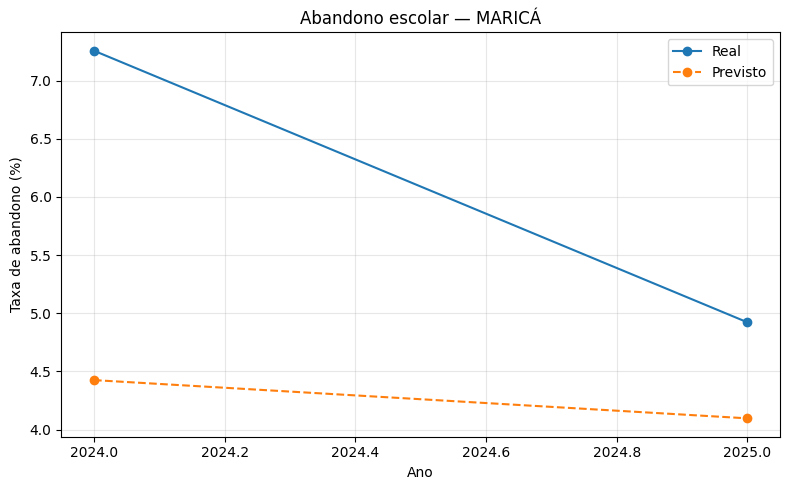

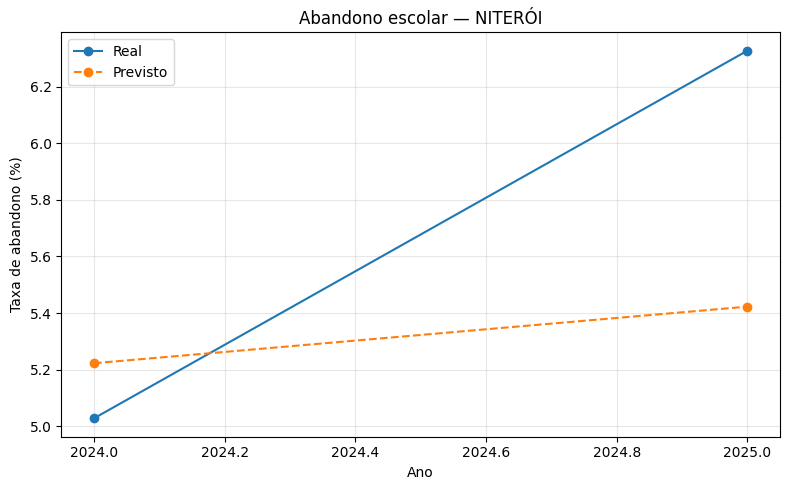

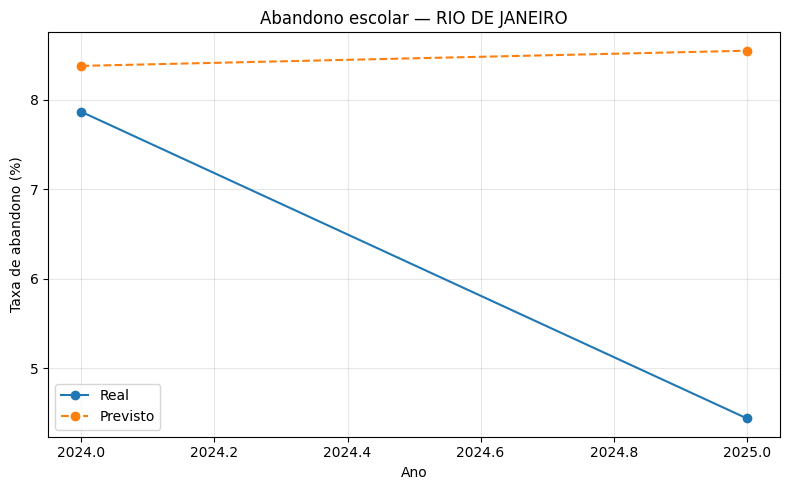

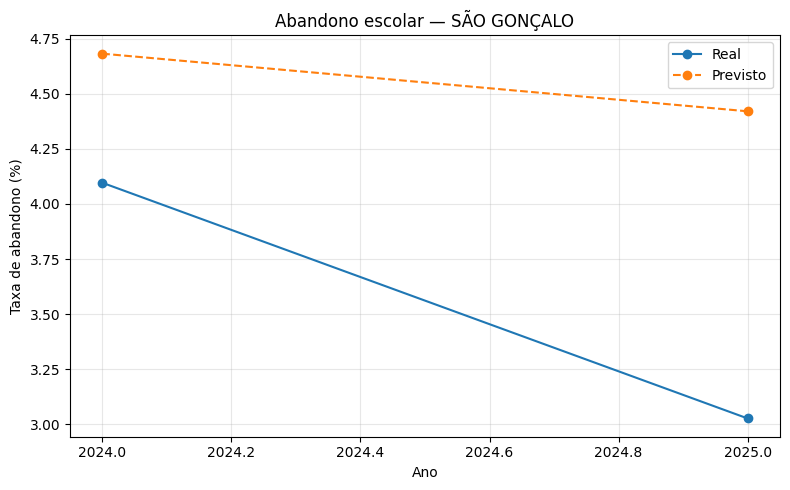

In [ ]:

# Adicionar matrículas ao DataFrame de resultados
resultados["Matriculados"] = (
    teste["Quantidade_de_Matriculados_Ensino_Medio"].to_numpy()
)

# Calcular médias ponderadas por município e ano
def media_ponderada(grupo, coluna):
    validos = grupo[[coluna, "Matriculados"]].dropna()

    if validos.empty or validos["Matriculados"].sum() == 0:
        return np.nan

    return np.average(
        validos[coluna],
        weights=validos["Matriculados"]
    )

resumo = resultados.groupby(
    ["Nome_do_Municipio", "Ano_do_Censo"]
).apply(
    lambda grupo: pd.Series({
        "Real": media_ponderada(grupo, "Real"),
        "Previsto": media_ponderada(grupo, modelo_coluna)
    }),
    include_groups=False
).reset_index()

# Gerar um gráfico para cada município
for municipio in resumo["Nome_do_Municipio"].unique():
    dados_municipio = resumo[
        resumo["Nome_do_Municipio"] == municipio
    ].sort_values("Ano_do_Censo")

    plt.figure(figsize=(8, 5))

    plt.plot(
        dados_municipio["Ano_do_Censo"],
        dados_municipio["Real"],
        marker="o",
        label="Real"
    )

    plt.plot(
        dados_municipio["Ano_do_Censo"],
        dados_municipio["Previsto"],
        marker="o",
        linestyle="--",
        label="Previsto"
    )

    plt.xlabel("Ano")
    plt.ylabel("Taxa de abandono (%)")
    plt.title(f"Abandono escolar — {municipio}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()



                  Modelo    MAE   RMSE     R2
0   OneHot_com_2020_2021  5.300  7.002  0.074
1   OneHot_sem_2020_2021  5.875  7.191  0.023
2  Efeitos_com_2020_2021  5.300  7.002  0.074
3  Efeitos_sem_2020_2021  5.875  7.191  0.023


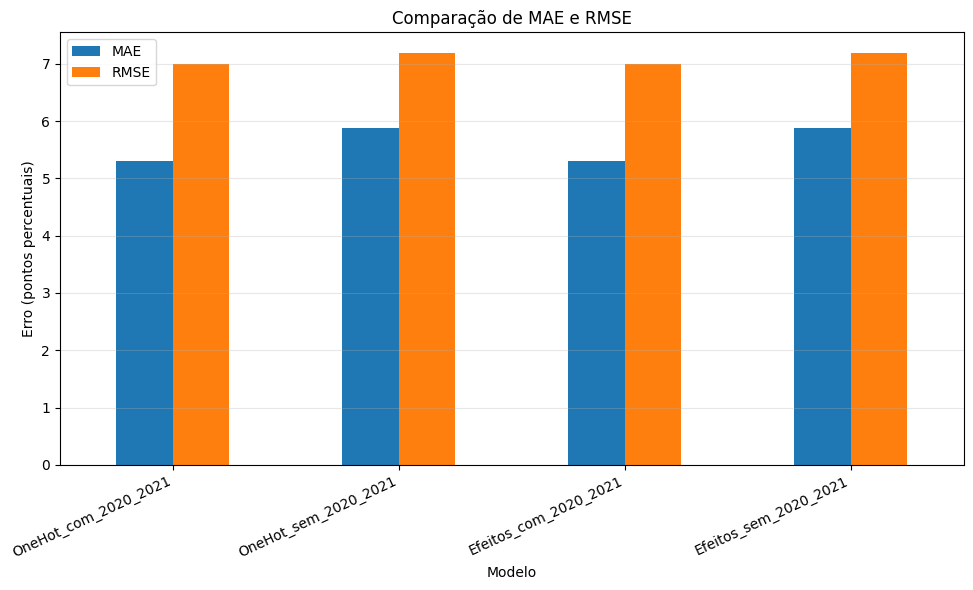

In [ ]:
modelos = [
    "OneHot_com_2020_2021",
    "OneHot_sem_2020_2021",
    "Efeitos_com_2020_2021",
    "Efeitos_sem_2020_2021"
]

metricas = []

for nome in modelos:
    metricas.append({
        "Modelo": nome,
        "MAE": mean_absolute_error(
            resultados["Real"], resultados[nome]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            resultados["Real"], resultados[nome]
        )),
        "R2": r2_score(resultados["Real"], resultados[nome])
    })

metricas = pd.DataFrame(metricas)
print(metricas.round(3))

metricas.plot(
    x="Modelo",
    y=["MAE", "RMSE"],
    kind="bar",
    figsize=(10, 6)
)

plt.ylabel("Erro (pontos percentuais)")
plt.title("Comparação de MAE e RMSE")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
